In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/iris/Iris.csv
/kaggle/input/datasets/uciml/iris/database.sqlite


IRIS DATASET

Dataset Shape:
(150, 6)

Column Names:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

First 5 Rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3  

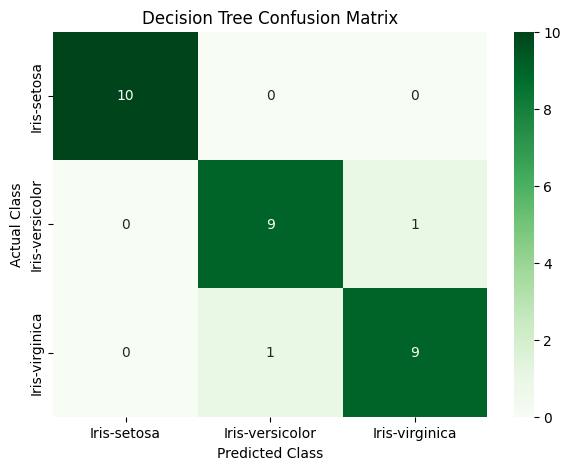


DECISION TREE FEATURE IMPORTANCE
SepalLengthCm = 0.0066
SepalWidthCm = 0.0146
PetalLengthCm = 0.672
PetalWidthCm = 0.3068


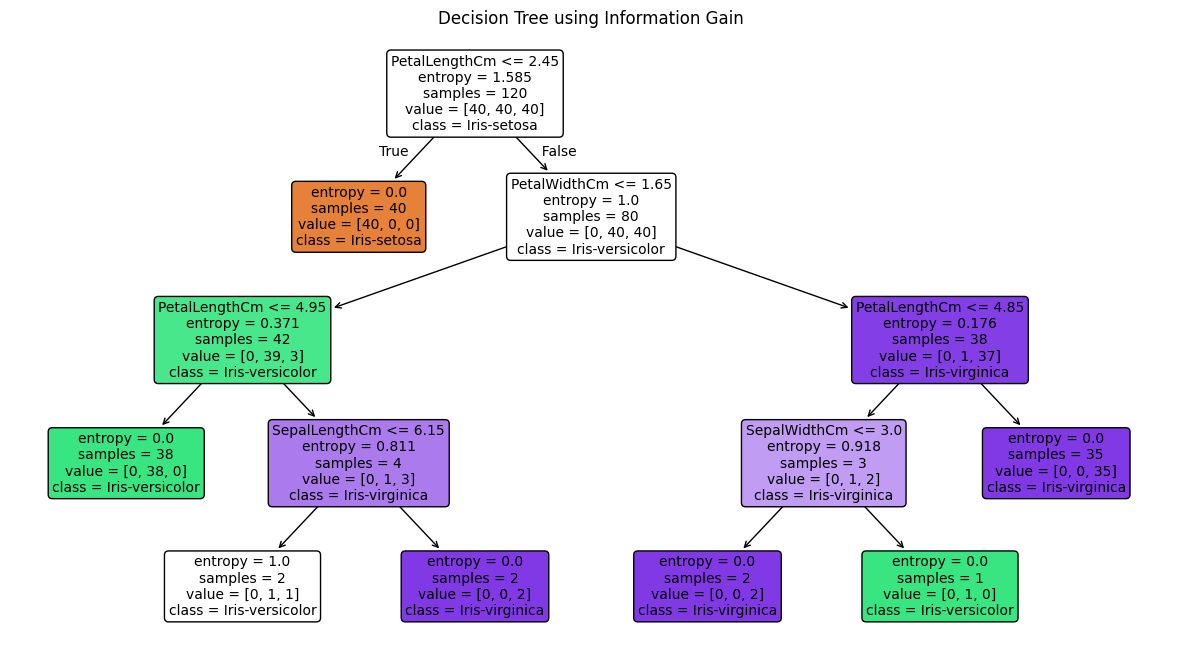


SVM RESULTS

Accuracy:
96.67%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


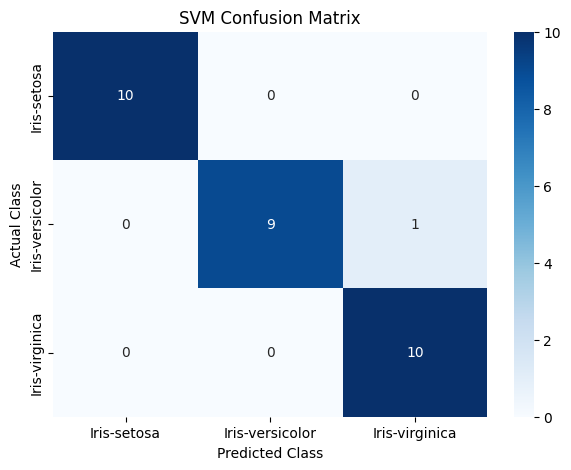


SVM SUPPORT VECTORS
Number of Support Vectors: 47
Support Vectors per Class: [10 18 19]


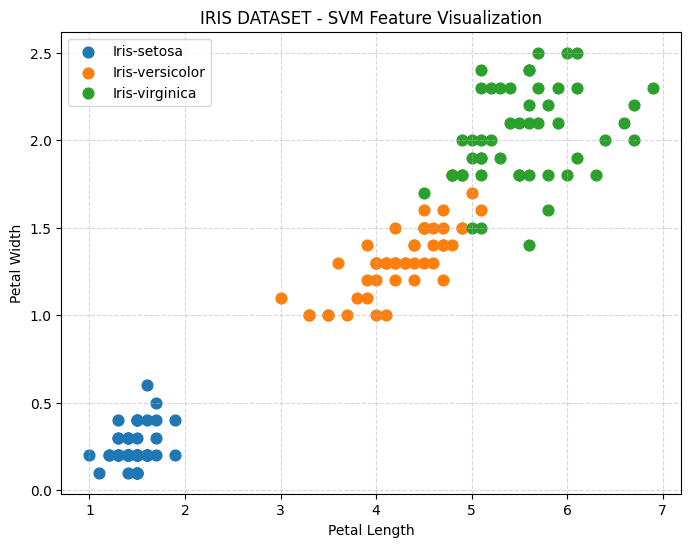


MODEL ACCURACY COMPARISON
Decision Tree Accuracy : 93.33%
SVM Accuracy           : 96.67%

IRIS FLOWER CLASSIFICATION

Choose a model:
1. Decision Tree
2. SVM
3. Compare Both
4. Exit


KeyboardInterrupt: Interrupted by user

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

path = "/kaggle/input/datasets/uciml/iris/Iris.csv"

df = pd.read_csv(path)

print("=" * 60)
print("IRIS DATASET")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe())

print("\nClass Distribution:")
print(df["Species"].value_counts())

features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = df[features]
y = df["Species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("\n" + "=" * 60)
print("DATASET SPLIT")
print("=" * 60)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

decision_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=4,
    random_state=42
)

decision_tree.fit(X_train, y_train)

dt_pred = decision_tree.predict(X_test)

dt_accuracy = accuracy_score(
    y_test,
    dt_pred
)

print("\n" + "=" * 60)
print("DECISION TREE RESULTS")
print("=" * 60)

print("\nAccuracy:")
print(f"{dt_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        dt_pred
    )
)

dt_cm = confusion_matrix(
    y_test,
    dt_pred
)

print("\nConfusion Matrix:")
print(dt_cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=decision_tree.classes_,
    yticklabels=decision_tree.classes_
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

print("\n" + "=" * 60)
print("DECISION TREE FEATURE IMPORTANCE")
print("=" * 60)

for feature, importance in zip(
    features,
    decision_tree.feature_importances_
):
    print(
        feature,
        "=",
        round(importance, 4)
    )

plt.figure(figsize=(15, 8))

plot_tree(
    decision_tree,
    feature_names=features,
    class_names=decision_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree using Information Gain")
plt.show()

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

svm_pred = svm_model.predict(
    X_test_scaled
)

svm_accuracy = accuracy_score(
    y_test,
    svm_pred
)

print("\n" + "=" * 60)
print("SVM RESULTS")
print("=" * 60)

print("\nAccuracy:")
print(f"{svm_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        svm_pred
    )
)

svm_cm = confusion_matrix(
    y_test,
    svm_pred
)

print("\nConfusion Matrix:")
print(svm_cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

print("\n" + "=" * 60)
print("SVM SUPPORT VECTORS")
print("=" * 60)

print(
    "Number of Support Vectors:",
    len(svm_model.support_)
)

print(
    "Support Vectors per Class:",
    svm_model.n_support_
)

plt.figure(figsize=(8, 6))

for species in df["Species"].unique():

    data = df[df["Species"] == species]

    plt.scatter(
        data["PetalLengthCm"],
        data["PetalWidthCm"],
        s=60,
        label=species
    )

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.title(
    "IRIS DATASET - SVM Feature Visualization"
)

plt.legend()

plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

plt.show()

print("\n" + "=" * 60)
print("MODEL ACCURACY COMPARISON")
print("=" * 60)

print(
    f"Decision Tree Accuracy : {dt_accuracy * 100:.2f}%"
)

print(
    f"SVM Accuracy           : {svm_accuracy * 100:.2f}%"
)

print("\n" + "=" * 60)
print("IRIS FLOWER CLASSIFICATION")
print("=" * 60)

print("\nChoose a model:")
print("1. Decision Tree")
print("2. SVM")
print("3. Compare Both")
print("4. Exit")

choice = input(
    "\nEnter your choice (1-4): "
)

if choice == "4":

    print("\nProgram ended.")

elif choice in ["1", "2", "3"]:

    print("\n" + "=" * 60)
    print("ENTER IRIS FLOWER MEASUREMENTS")
    print("=" * 60)

    try:

        sepal_length = float(
            input("Sepal Length (cm): ")
        )

        sepal_width = float(
            input("Sepal Width (cm): ")
        )

        petal_length = float(
            input("Petal Length (cm): ")
        )

        petal_width = float(
            input("Petal Width (cm): ")
        )

    except ValueError:

        print("\nPlease enter numbers only.")
        exit()

    new_flower = pd.DataFrame(
        [[
            sepal_length,
            sepal_width,
            petal_length,
            petal_width
        ]],
        columns=features
    )

    if choice == "1":

        prediction = decision_tree.predict(
            new_flower
        )

        print("\n" + "=" * 60)
        print("DECISION TREE PREDICTION")
        print("=" * 60)

        print(
            "\nPredicted Species:",
            prediction[0]
        )

    elif choice == "2":

        new_flower_scaled = scaler.transform(
            new_flower
        )

        prediction = svm_model.predict(
            new_flower_scaled
        )

        print("\n" + "=" * 60)
        print("SVM PREDICTION")
        print("=" * 60)

        print(
            "\nPredicted Species:",
            prediction[0]
        )

    elif choice == "3":

        dt_prediction = decision_tree.predict(
            new_flower
        )

        new_flower_scaled = scaler.transform(
            new_flower
        )

        svm_prediction = svm_model.predict(
            new_flower_scaled
        )

        print("\n" + "=" * 60)
        print("BOTH MODEL PREDICTIONS")
        print("=" * 60)

        print(
            "\nDecision Tree Prediction:",
            dt_prediction[0]
        )

        print(
            "SVM Prediction:",
            svm_prediction[0]
        )

        if dt_prediction[0] == svm_prediction[0]:

            print(
                "\nBoth models predicted the same species."
            )

        else:

            print(
                "\nThe models predicted different species."
            )

else:

    print("\nInvalid choice!")
    print("Please choose 1, 2, 3, or 4.")

print("\n" + "=" * 60)
print("IRIS CLASSIFICATION PROGRAM COMPLETED")
print("=" * 60)
